# 08B.5 — Scouting decision intelligence

**Objective O5 — scouting decision value.** A defensible tool for comparing prospects, built on the descriptive Athletic Fingerprint Scorecard of 07D — not a model result.

| Who | Question this notebook supports |
|---|---|
| Scout | Which prospects have genuinely different measured speed-development profiles despite similar official testing? |
| Coach | Which recorded movement characteristics are well supported and worth investigating further? |
| General manager | What is reliable, what duplicates the stopwatch, and what cannot yet influence a draft decision? |

These are **information-support** uses. Nothing here shows that a scouting decision improves.

**Scorecard — four sections, never combined.** A · Speed capacity (official tests and supported tracked speed) · B · Speed development (measured speed-band progression with uncertainty) · C · Movement fingerprint (TCN-based similarity only) · D · Evidence confidence (recording quality, attempts, support, limits). There is **no total score and no NFL-potential grade**: no section has an established NFL predictive value.

**What this notebook adds to 07D.** Explicit abstention states · pairwise tests on the *difference* of two athletes (two overlapping individual intervals are not a test) · repeat-attempt stability of a percentile · sensitivity to the reference population · real comparison cases selected by pre-draft rules · a football-outcome panel that appears only if 08B.2 found a credible result, with the wording its validation status allows.

**Prerequisites (same `RUN_MODE`).** 00, 01, 02, 04A, 06B, 07D. Optional: 08B.0, 08B.2 (football panel), 08B.4 (information summary). No NFL value enters a pre-draft table.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False         # interface parity: every table of this notebook is recomputed on each run (seconds)
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '08B5.1'
REGISTRY_VERSION = 'v1'       # football registry (only for the separate football panel)
CASES_PER_TYPE = 2            # comparison cases kept per declared case type
MAX_SCORECARDS = 4            # full scorecards drawn (athletes of the first cases)
MIN_REFERENCE = 30            # athletes of a position needed before a percentile is computed (the 07D rule)
SHOW_TABLES = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

from dataclasses import replace

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import read_json, utc_now
from nflbdb.research.advanced_movement import atlas as at
from nflbdb.research.advanced_movement import checkpoint as ck
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import football_figures as ff
from nflbdb.research.advanced_movement import football_registry as fr
from nflbdb.research.advanced_movement import football_transfer as ft
from nflbdb.research.advanced_movement import football_validation as fv
from nflbdb.research.advanced_movement import movement_information as mi
from nflbdb.research.advanced_movement import scouting_intelligence as si
from nflbdb.research.advanced_movement import sequences as seq
from nflbdb.research.advanced_movement.artifacts import FootballStore, MissingArtifactError
from nflbdb.research.advanced_movement.scoring import figures as sfig
from nflbdb.research.advanced_movement.scoring import fingerprint as fp
from nflbdb.research.advanced_movement.scoring import percentiles as pc
from nflbdb.research.advanced_movement.scoring import scorecards as sc
from nflbdb.research.advanced_movement.scoring import uncertainty as un

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
if controls.smoke:
    MIN_REFERENCE = 5
store = FootballStore(cfg, controls)
up, T, SC = store.upstream, store.transfer, store.scoring
amc.seed_everything(controls.seed)
NB = {'01': '01_sequence_eda_and_alignment.ipynb', '02': '02_functional_pca_baseline.ipynb', '04A': '04a_feature_characteristic_atlas.ipynb',
      '06B': '06b_combine_to_nfl_transfer_benchmark.ipynb', '07D': '07d_athletic_fingerprint_scorecard.ipynb',
      '08B5': '08b5_scouting_decision_intelligence.ipynb'}

def optional(fn, what):
    try:
        return fn()
    except MissingArtifactError as e:
        print(f'OPTIONAL INPUT ABSENT — {what}: {e}')
        return None

# ---- the executed 07D scorecard (pre-draft tables; READ ONLY)
profile = SC.require(sc.PROFILE, NB['07D'])
pct = pl.concat([SC.require(replace(pc.PCT, name=n), NB['07D']) for n in ('combine_speed_percentiles', 'combine_speed_development_percentiles')]).unique(
    subset=['nfl_id', 'feature_id'], maintain_order=True)
confidence = SC.require(sc.CONFIDENCE, NB['07D'])
neighbors = SC.require(fp.NEIGHBORS, NB['07D'])
attempt_values = store.atlas.require(at.ATTEMPT_VALUES, NB['04A'])
windows = up.require(ck.WINDOWS, NB['02'])
frames = optional(lambda: up.require(seq.SEQ_FRAMES, NB['01']), 'sequence frames (sprint-curve overlay)')
rep = optional(lambda: T.require_named('transfer_attempt_representations_outer', NB['06B']), 'fold-fitted TCN representation (fingerprint distance)')
for name, df in (('profile', profile), ('percentiles', pct), ('confidence', confidence)):
    sc.assert_no_nfl_columns(df, name)
ORDER = dict(zip(windows['seq_id'].to_list(), windows['attempt_order'].to_list()))
POSITION = dict(zip(profile['nfl_id'].to_list(), profile['position_group'].to_list()))
NAME = {i: (n or str(i)) for i, n in zip(profile['nfl_id'].to_list(), profile['display_name'].to_list())}
DIST = fp.distance_lookup(fp.fold_embeddings(rep, ORDER)) if rep is not None else None
FEATURE_LABELS = {f.feature_id: f.label for f in pc.FEATURES}

PROV = {'notebook': NB['08B5'], 'experiment_version': EXPERIMENT_VERSION, 'run_mode': controls.run_mode, 'seed': controls.seed, 'cases_per_type': CASES_PER_TYPE,
        'min_reference': MIN_REFERENCE, 'nfl_inputs_of_pre_draft_tables': 'none'}
save = lambda df, c: store.write(df, c, '08B5', PROV) if controls.save_tables else df
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {profile.height} Combine profiles · {pct.height} scorecard cells · '
                 f'fingerprint distance {"available" if DIST is not None else "NOT available"} · {sc.PROFILE.name} carries `nfl_predictive_status` = '
                 f'{profile["nfl_predictive_status"][0]!r}'))
display(store.describe())

**Run mode: `full`** (FULL) · 510 Combine profiles · 2040 scorecard cells · fingerprint distance available · combine_athletic_scorecard_profiles carries `nfl_predictive_status` = 'DESCRIPTIVE ONLY — not validated as a predictor of NFL movement or performance (Milestone 06: no incremental gain over official Combine testing was established)'

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Synthetic checks

Percentile orientation and leave-one-out references, pairwise uncertainty on differences, abstention states, case selection without NFL information, and the rule that no football panel exists without a valid executed result.

In [3]:
validation = fv.run_all((fv.check_pairwise_uncertainty_and_abstention, fv.check_percentile_orientation_and_attempt_shifts,
                         fv.check_case_selection_uses_no_nfl_information))
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(validation)
fv.assert_all_passed(validation)

check,status,detail
str,str,str
"""pairwise_uncertainty_and_abstention""","""PASS""","""pairwise tests on differences; not_observed / insufficient_evidence instead of imputed values"""
"""percentile_orientation_and_attempt_shifts""","""PASS""","""oriented percentiles, leave-one-out references, repeat-attempt shifts and reference sensitivity"""
"""case_selection_uses_no_nfl_information""","""PASS""","""cases chosen by pre-draft rules only; NFL-named inputs refused; no football panel without validation"""


## 2 · Abstention — the evidence state of every scorecard cell

| State | Meaning |
|---|---|
| `supported` | an official result, or a tracked value with an estimated measurement error |
| `experimental` | shown with its interval; reliability of the athlete value below the *available* line |
| `insufficient_evidence` | the position does not support the measure, or its measurement error cannot be estimated |
| `not_observed` | the quantity was not recorded for this athlete |

A missing measurement is never imputed and never read as a low value: athletic ability is not inferred from an absent recording.

In [4]:
states = save(si.state_table(pct), si.STATE_T)
with pl.Config(tbl_rows=-1, tbl_width_chars=200):
    display(states.group_by('feature_id', 'state').len().sort('feature_id', 'state'))

23:42:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] scouting_evidence_states: 2,040 rows → warehouse/gold/advanced_movement/football_v1/scouting_evidence_states.parquet


feature_id,state,len
str,str,u32
"""F2.forty.p95_speed""","""not_observed""",109
"""F2.forty.p95_speed""","""supported""",401
"""F6.forty.time_v4_to_v8_s""","""not_observed""",109
"""F6.forty.time_v4_to_v8_s""","""supported""",401
"""cmb_forty""","""not_observed""",86
"""cmb_forty""","""supported""",424
"""cmb_ten_yd_split""","""not_observed""",85
"""cmb_ten_yd_split""","""supported""",425


## 3 · Ranking uncertainty — repeat attempts and reference population

- **Repeat-attempt stability.** For every athlete with two valid attempts: the position percentile of each attempt against the same reference (the other athletes of his position). The shift is what a scout would not know from a single run.
- **Position reference.** The same value scored against the own position and against all positions pooled.
- **Cohort reference.** All draft cohorts versus one cohort as the reference.

A percentile is a statement about a comparison group; these tables say how much of it is the choice of the group.

In [5]:
TRACKED = [pc.P95, pc.V4_V8]
shifts = save(pl.concat([si.attempt_shifts(f, attempt_values, ORDER, POSITION, pc.FEATURE[f].higher_is_better, MIN_REFERENCE) for f in TRACKED]), si.SHIFTS)
shift_summary = save(si.shift_summary(shifts), si.SHIFT_SUMMARY)

pos_rows, coh_rows = [], []
for fid in (pc.FORTY, pc.P95, pc.V4_V8):
    t = pct.filter(pl.col('feature_id') == fid)
    if t.is_empty():
        continue
    v = t['value'].cast(pl.Float64).fill_null(np.nan).to_numpy()
    p = np.asarray(t['position_group'].to_list(), dtype=str)
    y = t['draft_year'].cast(pl.Float64).fill_null(-1.0).to_numpy()
    ref = t['in_reference'].fill_null(False).to_numpy()
    hib = pc.FEATURE[fid].higher_is_better
    pos_rows += si.position_reference_sensitivity(fid, v, p, ref, hib, MIN_REFERENCE)
    coh_rows += [{'feature_id': fid, **r} for r in un.cohort_sensitivity(v, p, y, ref, hib, MIN_REFERENCE) if r['cohort'] > 0]
ref_sens = save(si.reference_sensitivity_table(pos_rows, coh_rows), si.REF_SENS)
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=220):
        display(shift_summary)
        display(ref_sens)

23:42:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] scouting_attempt_percentile_shifts: 750 rows → warehouse/gold/advanced_movement/football_v1/scouting_attempt_percentile_shifts.parquet
23:42:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] scouting_repeat_attempt_stability: 12 rows → warehouse/gold/advanced_movement/football_v1/scouting_repeat_attempt_stability.parquet
23:42:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] scouting_reference_sensitivity: 57 rows → warehouse/gold/advanced_movement/football_v1/scouting_reference_sensitivity.parquet


feature_id,position_group,n_athletes,median_abs_shift,p90_abs_shift,share_within_10,spearman
str,str,i64,f64,f64,f64,f64
"""F2.forty.p95_speed""","""ALL""",375,5.434783,20.430108,0.712,0.921548
"""F2.forty.p95_speed""","""DB""",93,6.930693,22.772277,0.688172,0.912939
"""F2.forty.p95_speed""","""DL""",84,3.26087,11.956522,0.845238,0.977297
"""F2.forty.p95_speed""","""OL""",84,5.851064,18.829787,0.690476,0.93203
"""F2.forty.p95_speed""","""TE""",32,3.030303,27.272727,0.6875,0.893067
"""F2.forty.p95_speed""","""WR""",82,7.526882,24.301075,0.634146,0.900441
"""F6.forty.time_v4_to_v8_s""","""ALL""",375,10.638298,39.207921,0.485333,0.735776
"""F6.forty.time_v4_to_v8_s""","""DB""",93,13.861386,42.178218,0.387097,0.658372
"""F6.forty.time_v4_to_v8_s""","""DL""",84,5.434783,26.086957,0.738095,0.909071


feature_id,reference_kind,position_group,alternative,n_scored,n_reference_alternative,mean_abs_shift,max_abs_shift
str,str,str,str,i64,i64,f64,f64
"""cmb_forty""","""position""","""DB""","""all positions pooled""",104,424,22.844476,43.768142
"""cmb_forty""","""position""","""DL""","""all positions pooled""",94,424,15.446752,32.645022
"""cmb_forty""","""position""","""OL""","""all positions pooled""",95,424,34.837388,67.996524
"""cmb_forty""","""position""","""TE""","""all positions pooled""",34,424,18.50701,33.407325
"""cmb_forty""","""position""","""WR""","""all positions pooled""",97,424,26.694709,45.185762
"""F2.forty.p95_speed""","""position""","""DB""","""all positions pooled""",95,401,23.18152,43.601523
"""F2.forty.p95_speed""","""position""","""DL""","""all positions pooled""",93,401,14.96193,32.818491
"""F2.forty.p95_speed""","""position""","""OL""","""all positions pooled""",93,401,33.727509,63.942295
"""F2.forty.p95_speed""","""position""","""TE""","""all positions pooled""",34,401,16.974648,31.322429


## 4 · Comparison cases — selected by pre-draft rules only

Five declared case types:

1. similar official forty, different speed development;
2. similar tracked top speed, different speed development (a different sprint curve);
3. similar body and official forty, distant movement fingerprints;
4. similar official forty, high versus low measurement confidence;
5. similar official forty, stable versus unstable repeat attempts.

The rule is deterministic: among matched pairs of a position, the largest contrast first; no athlete in two cases of a type. The tables it reads are checked for NFL-named columns and refused if one is found. The cases are **illustrations of what the scorecard shows — not evidence**, and no favourable player is picked from an NFL label.

**Pairwise uncertainty.** For each pair and feature: the difference, the standard error of the *difference* (from repeat-attempt variation of both athletes) and a verdict. An official result has no repeat-attempt error here: its difference is shown without a verdict.

In [6]:
cases = save(si.select_cases(profile, pct, shifts, DIST, CASES_PER_TYPE), si.CASES)
pairwise = save(si.pairwise_table(pct, cases), si.PAIRWISE)
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=90):
    display(cases.select('criterion', 'rank', 'position_group', 'name_a', 'name_b', 'matched_on', 'contrast', 'contrast_size', 'selected_using_nfl'))
    display(pairwise.select('case', 'nfl_id_a', 'nfl_id_b', 'feature_label', 'value_a', 'value_b', 'difference', 'se_difference', 'ci_lower', 'ci_upper', 'verdict'))
found = set(cases['case'].unique().to_list())
print('case types without a qualifying pair (reported, not forced):', [c for c, _ in si.CASE_TYPES if c not in found] or 'none')

23:42:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] scouting_comparison_cases: 10 rows → warehouse/gold/advanced_movement/football_v1/scouting_comparison_cases.parquet
23:42:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] scouting_pairwise_uncertainty: 40 rows → warehouse/gold/advanced_movement/football_v1/scouting_pairwise_uncertainty.parquet


criterion,rank,position_group,name_a,name_b,matched_on,contrast,contrast_size,selected_using_nfl
str,i64,str,str,str,str,str,f64,bool
"""similar official forty, different speed development""",1,"""DL""","""Nesta Jade Silvera""","""Justin Eboigbe""","""official forty within 0.02 s""","""speed development 4 → 8 yd/s, |z| of the difference""",7.644405,false
"""similar official forty, different speed development""",2,"""OL""","""Jarrett Patterson""","""Dominick Puni""","""official forty within 0.02 s""","""speed development 4 → 8 yd/s, |z| of the difference""",4.968342,false
"""similar tracked top speed, different speed development""",1,"""DL""","""Cedric Johnson""","""Kyle Kennard""","""tracked top speed within 0.05 yd/s""","""speed development 4 → 8 yd/s, |z| of the difference""",5.545862,false
"""similar tracked top speed, different speed development""",2,"""OL""","""Ryan Hayes""","""Tyler Booker""","""tracked top speed within 0.05 yd/s""","""speed development 4 → 8 yd/s, |z| of the difference""",5.482074,false
"""similar body and official forty, distant movement fingerprints""",1,"""OL""","""Anton Harrison""","""Troy Fautanu""","""weight within 5.0 lb, height within 1.0 in, forty within 0.03 s""","""TCN-B fingerprint distance""",1.158633,false
"""similar body and official forty, distant movement fingerprints""",2,"""DB""","""DeMarcco Hellams""","""Jaylen Key""","""weight within 5.0 lb, height within 1.0 in, forty within 0.03 s""","""TCN-B fingerprint distance""",1.066416,false
"""similar official forty, high versus low measurement confidence""",1,"""WR""","""Jonathan Mingo""","""Luke McCaffrey""","""official forty within 0.02 s""","""evidence tier high versus low (closest forty first)""",0.0,false
"""similar official forty, high versus low measurement confidence""",2,"""DB""","""Julius Brents""","""Ryan Watts""","""official forty within 0.02 s""","""evidence tier high versus low (closest forty first)""",0.0,false
"""similar official forty, stable versus unstable repeat attempts""",1,"""WR""","""Andrei Iosivas""","""Rakim Jarrett""","""official forty within 0.02 s""","""difference in the percentile shift between two attempts""",81.72043,false


case,nfl_id_a,nfl_id_b,feature_label,value_a,value_b,difference,se_difference,ci_lower,ci_upper,verdict
str,i64,i64,str,f64,f64,f64,f64,f64,f64,str
"""similar_forty_different_development""",56096,57226,"""official forty-yard dash""",5.16,5.18,0.02,null,null,null,"""insufficient_evidence"""
"""similar_forty_different_development""",56096,57226,"""official 10-yard split""",1.77,1.8,0.03,null,null,null,"""insufficient_evidence"""
"""similar_forty_different_development""",56096,57226,"""tracked top speed (p95)""",9.066239,9.286809,0.22057,0.093316,0.037675,0.403466,"""distinguishable"""
"""similar_forty_different_development""",56096,57226,"""speed development 4 → 8 yd/s""",1.724652,1.253881,-0.470771,0.061584,-0.591473,-0.350069,"""distinguishable"""
"""similar_forty_different_development""",56066,57207,"""official forty-yard dash""",5.33,5.35,0.02,null,null,null,"""insufficient_evidence"""
"""similar_forty_different_development""",56066,57207,"""official 10-yard split""",1.82,1.86,0.04,null,null,null,"""insufficient_evidence"""
"""similar_forty_different_development""",56066,57207,"""tracked top speed (p95)""",9.054334,8.889971,-0.164363,0.091293,-0.343293,0.014568,"""not_distinguishable"""
"""similar_forty_different_development""",56066,57207,"""speed development 4 → 8 yd/s""",1.592125,2.102363,0.510238,0.102698,0.308954,0.711522,"""distinguishable"""
"""similar_top_speed_different_curve""",57334,58330,"""official forty-yard dash""",4.63,4.73,0.1,null,null,null,"""insufficient_evidence"""


case types without a qualifying pair (reported, not forced): none


## 5 · Football-transfer integration — only what the validation status allows

An **experimental football-outcome panel** is added to the scorecard only when notebook 08B.2 ran on the current registry, passed Gate C, and a registered comparison reads as a held-out improvement or an exploratory positive association. Its wording is the strongest claim of the registry branch. Otherwise the scorecard stays descriptive and says so.

No draft-bust or hidden-star label is produced under any branch: the study does not support one.

In [7]:
try:
    REGISTRY = fr.load_registry(store, REGISTRY_VERSION)
except fr.FootballTransferBlocked as e:
    print('football registry not usable:', e)
    REGISTRY = None
BRANCH = fr.branch(REGISTRY)
m2_path = store.data_dir / 'football_transfer_manifest.json'
m2 = read_json(m2_path, {}) if m2_path.is_file() else {}
GATE_C_OK = bool(REGISTRY) and m2.get('gate_c') == 'PASS' and m2.get('registry_hash') == REGISTRY.get('version_hash')
FOOTBALL_HYP = store.read(ft.HYP) if (GATE_C_OK and store.exists(ft.HYP)) else None
PANEL = si.football_panel(BRANCH, FOOTBALL_HYP, GATE_C_OK)
info_registry = store.read(mi.REGISTRY) if store.exists(mi.REGISTRY) else None
if info_registry is None:
    print('08B.4 has no executed evidence registry for this run mode: the information summary lists the conventional and football rows only')
summary = save(si.information_summary(info_registry, PANEL), si.SUMMARY)
display(Markdown(f'**{PANEL["title"]}** — {PANEL["text"]}'))
with pl.Config(tbl_rows=-1, tbl_width_chars=300, fmt_str_lengths=200):
    display(summary.select('stakeholder', 'item', 'support', 'use', 'do_not_claim'))

23:42:38 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] scouting_information_summary: 14 rows → warehouse/gold/advanced_movement/football_v1/scouting_information_summary.parquet


**Football-outcome evidence: no added value established** — no registered Combine tracking model improved held-out prediction of the approved football outcome beyond official testing. The scorecard stays descriptive.

stakeholder,item,support,use,do_not_claim
str,str,str,str,str
"""general_manager""","""official Combine tests""","""conventional""","""as today""","""nothing new"""
"""general_manager""","""NFL predictive value of Combine tracking""","""not established""","""none in a draft model""","""talent rankings, NFL potential scores, bust or sleeper labels"""
"""scout""","""tracked top speed (p95)""","""reliable new measured information""","""the speed the athlete actually reached and held; confirms or questions the official forty""","""a football implication of the difference"""
"""coach""","""tracked top speed (p95)""","""worth a closer look""","""a measured interval to assess further""","""a training prescription from an observed difference"""
"""scout""","""speed development 4 → 8 yd/s""","""reliable new measured information""","""how quickly speed builds through the middle of the run; separates athletes with the same forty""","""a football implication of the difference"""
"""coach""","""speed development 4 → 8 yd/s""","""worth a closer look""","""a measured interval to assess further""","""a training prescription from an observed difference"""
"""scout""","""acceleration over 1 s from 4 yd/s""","""not repeatable""","""context for the official result only""","""a football implication of the difference"""
"""coach""","""acceleration over 1 s from 4 yd/s""","""no separate signal""","""a measured interval to assess further""","""a training prescription from an observed difference"""
"""scout""","""speed gain over 10 yd from 4 yd/s""","""weak additional information""","""context for the official result only""","""a football implication of the difference"""


## 6 · Scorecards and comparison figures

Real athletes, real recordings. Each scorecard shows the four sections side by side with their intervals and abstentions; the football panel text sits in section D and is the only place an NFL result may appear.

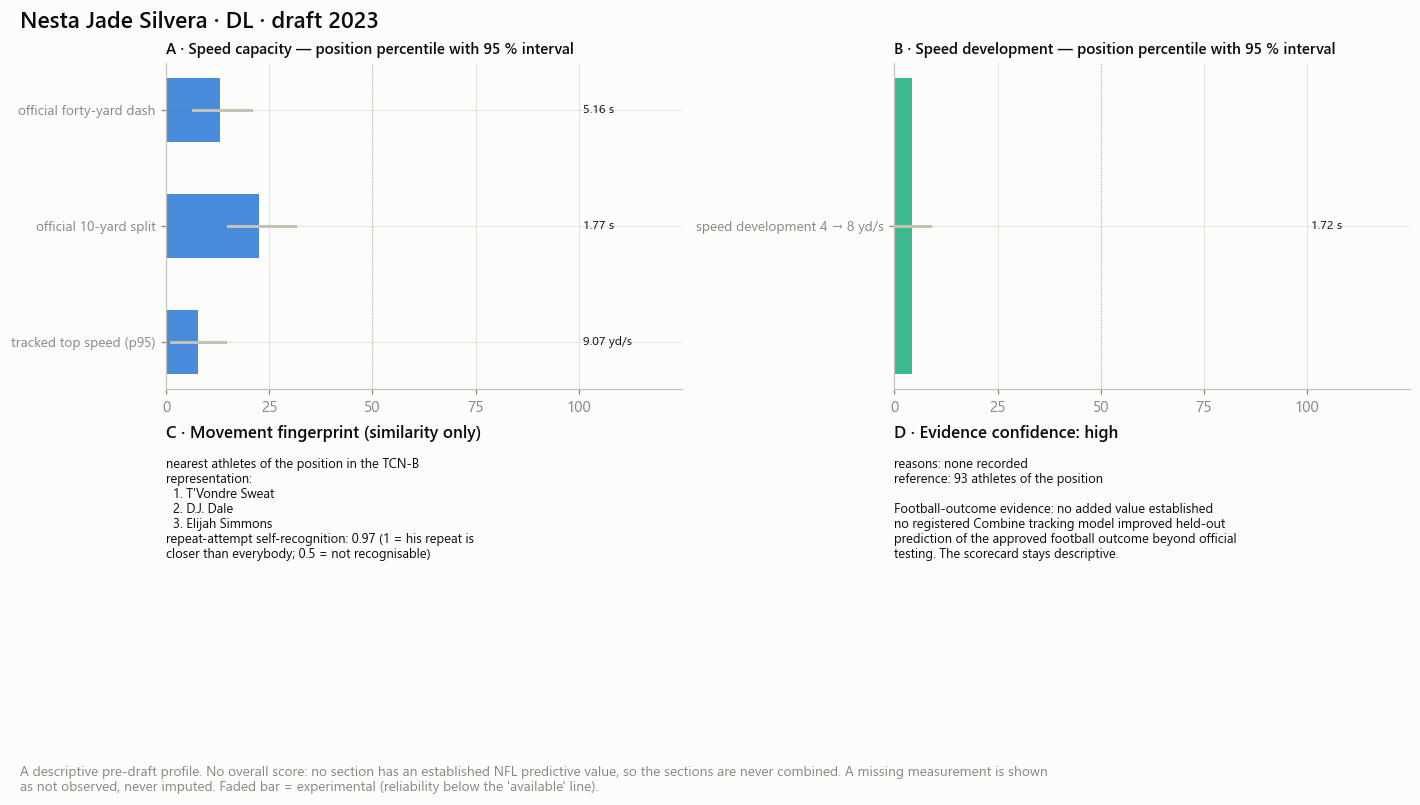

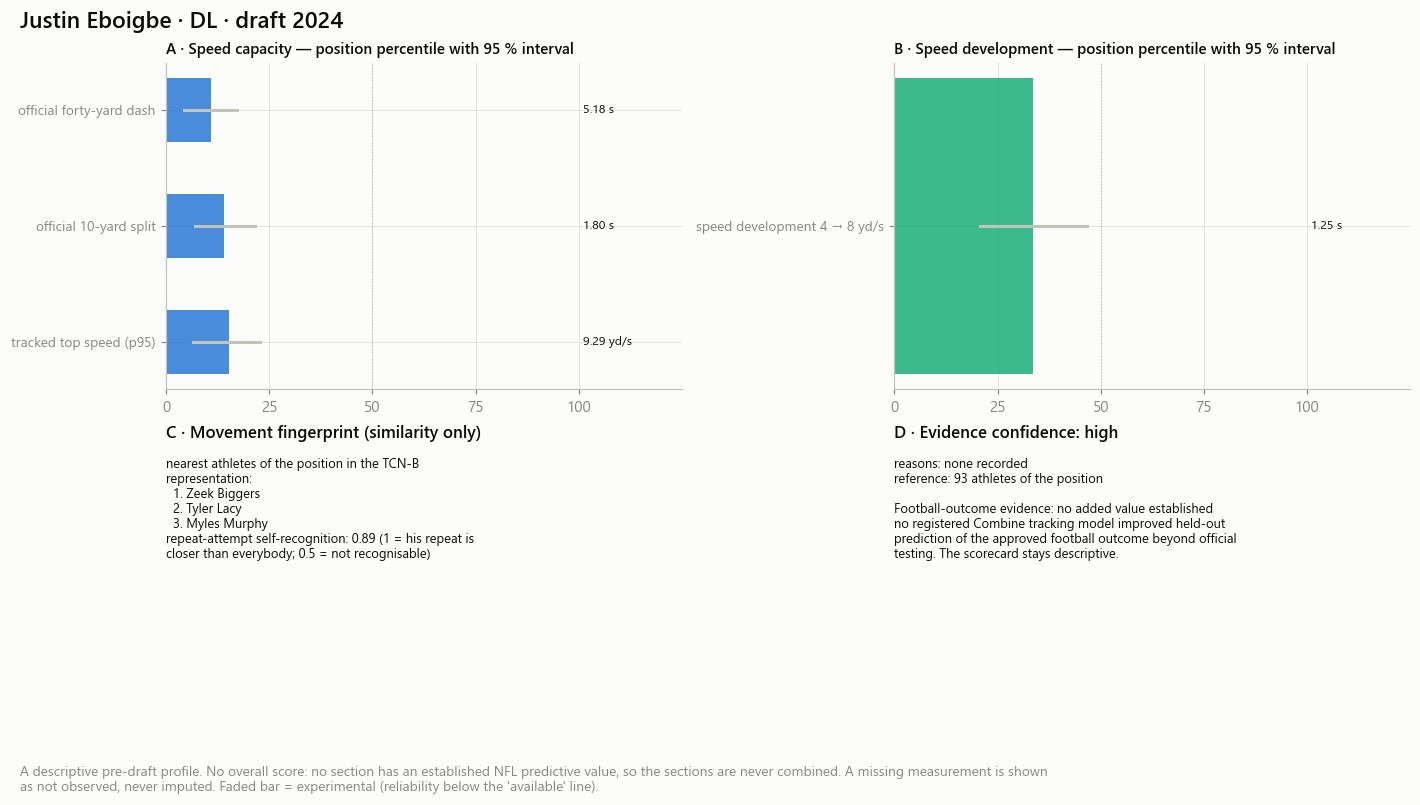

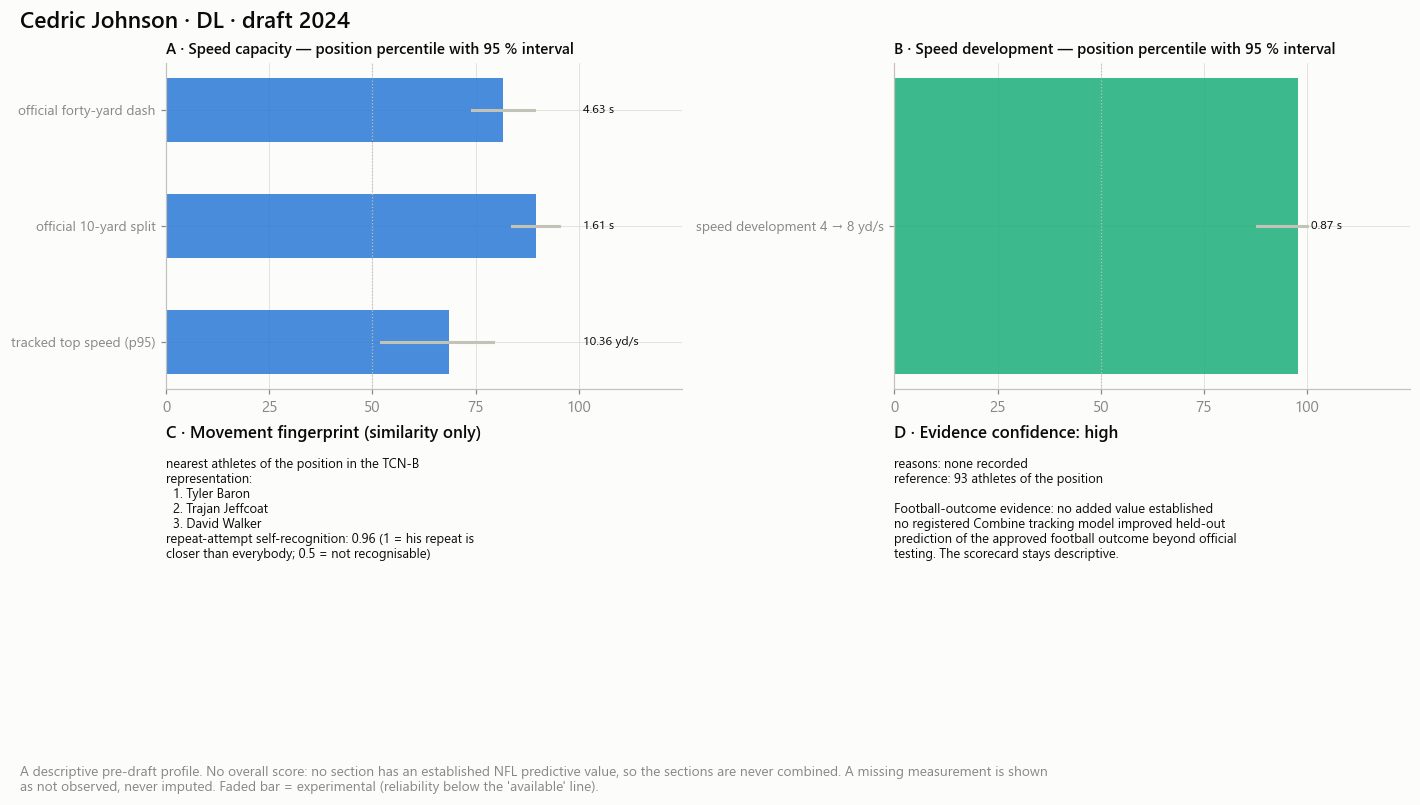

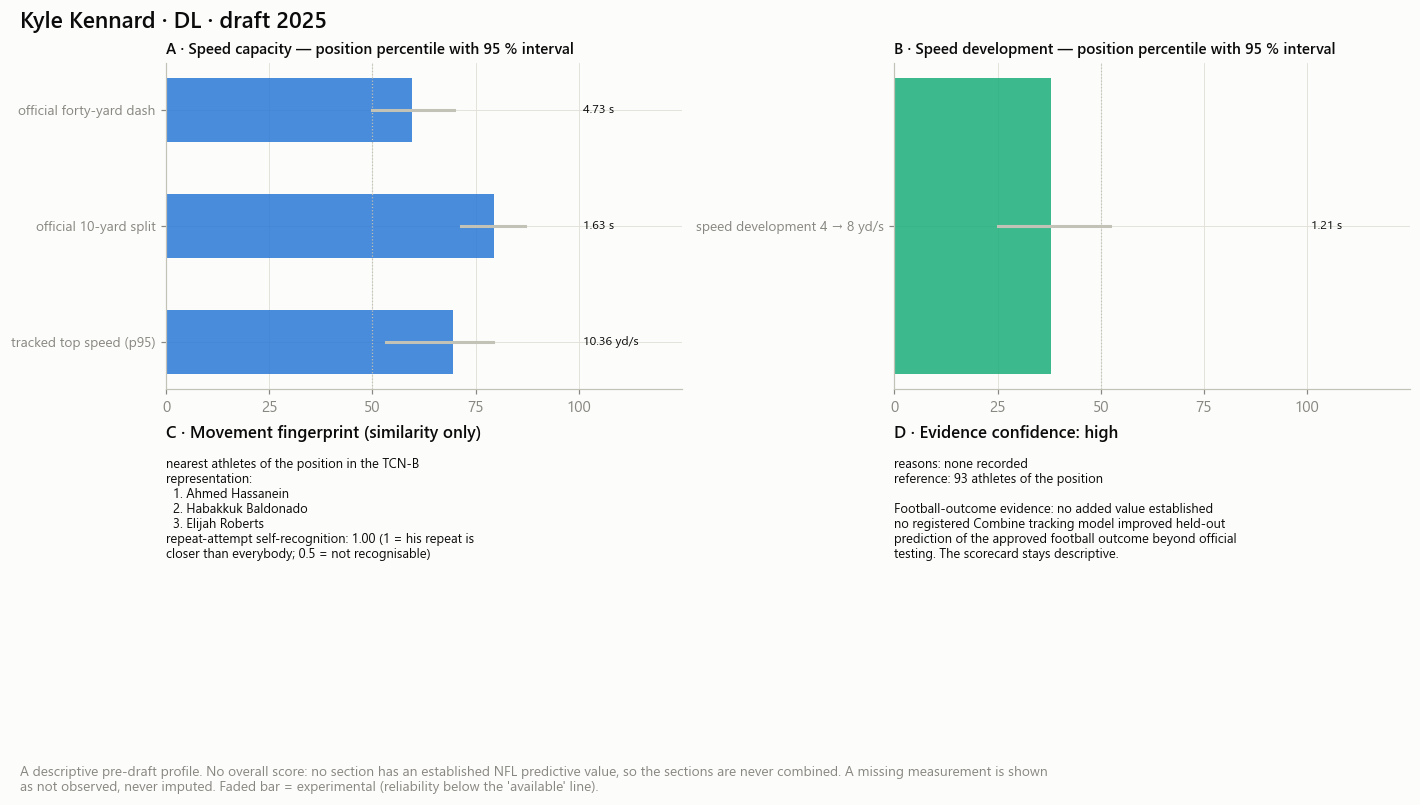

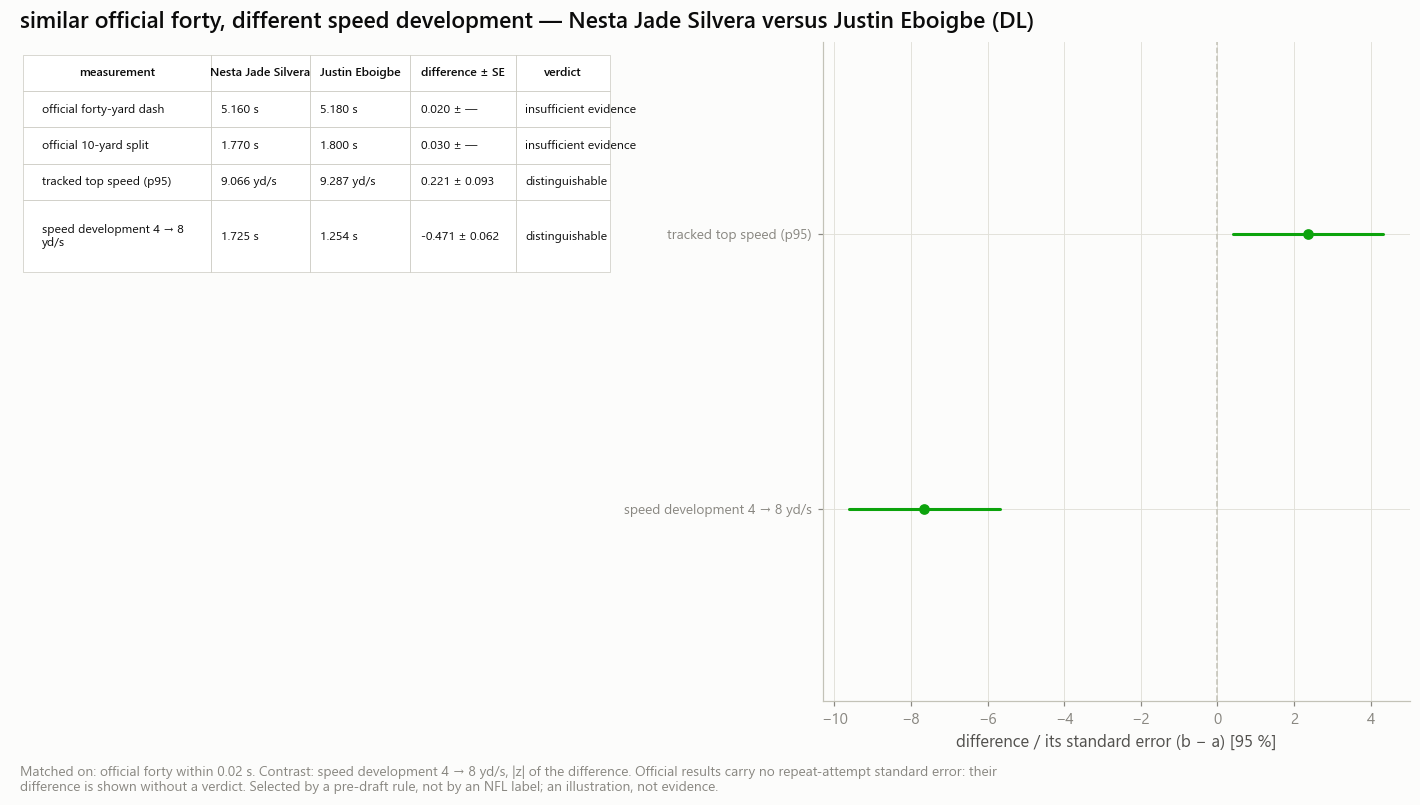

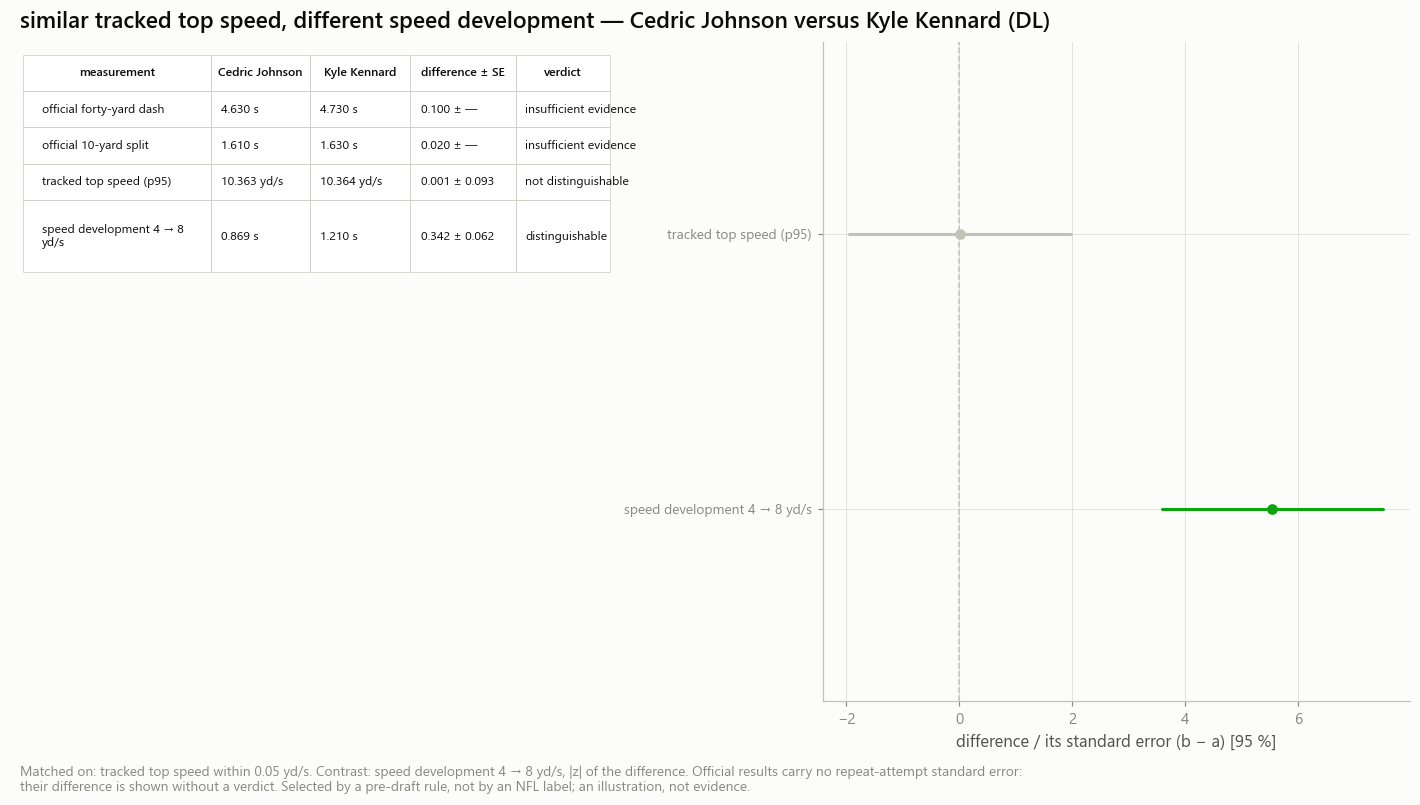

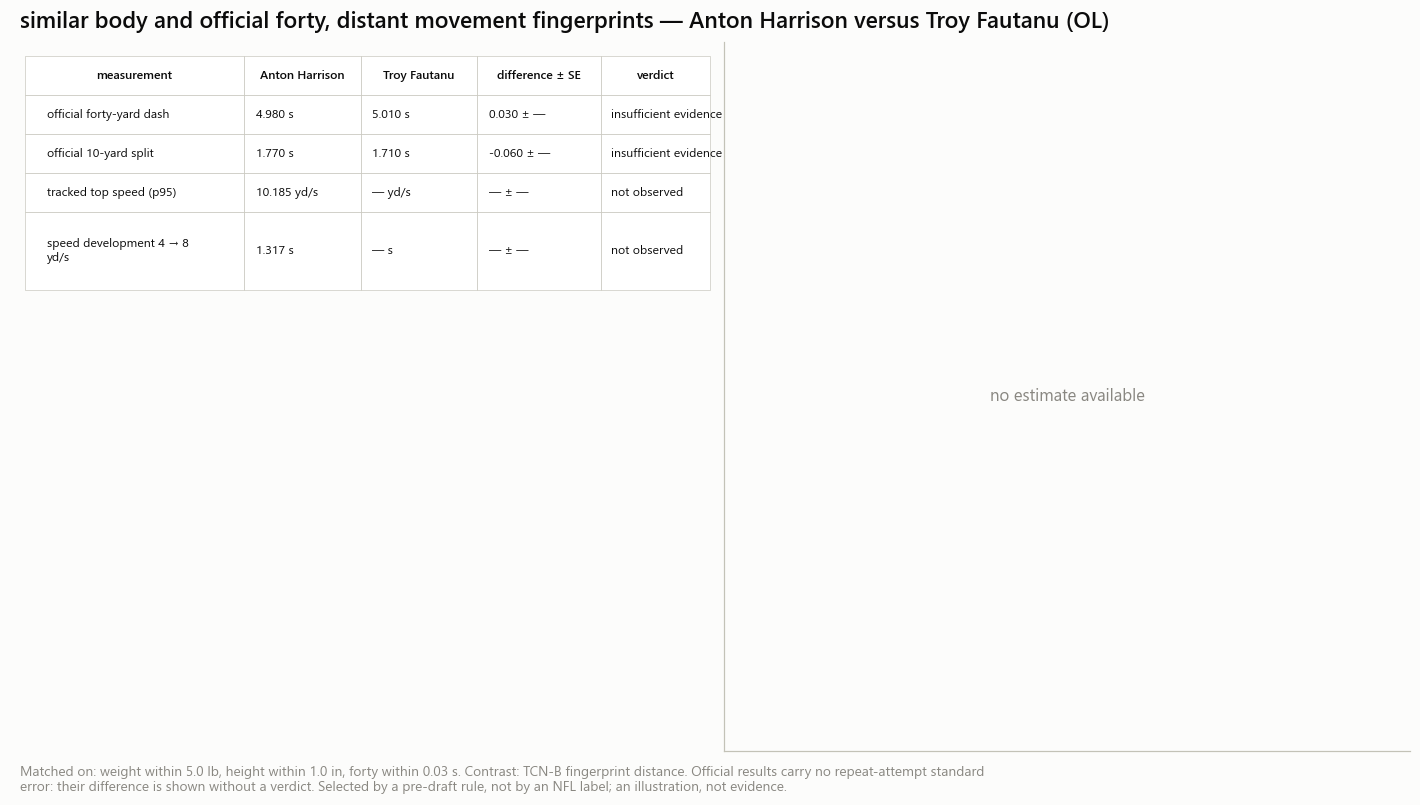

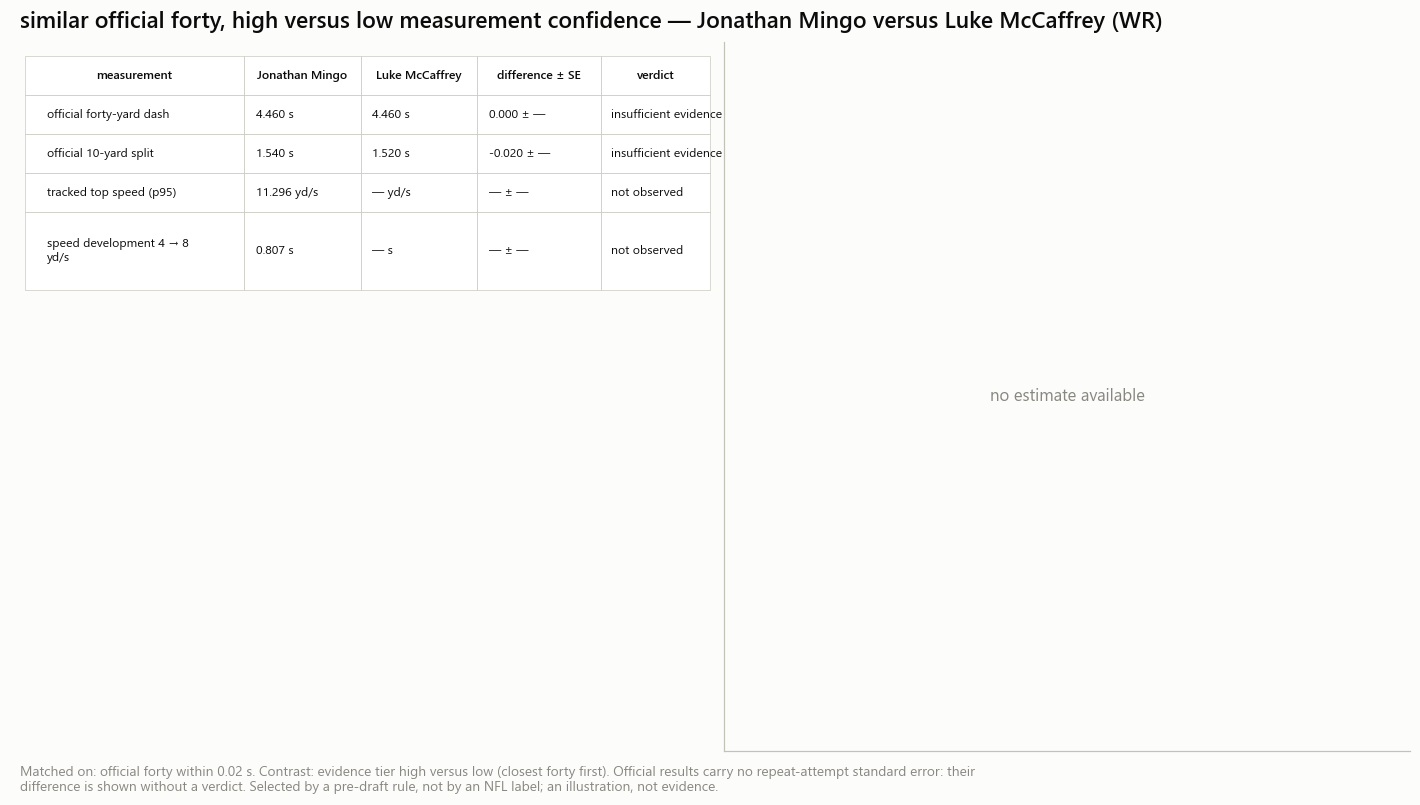

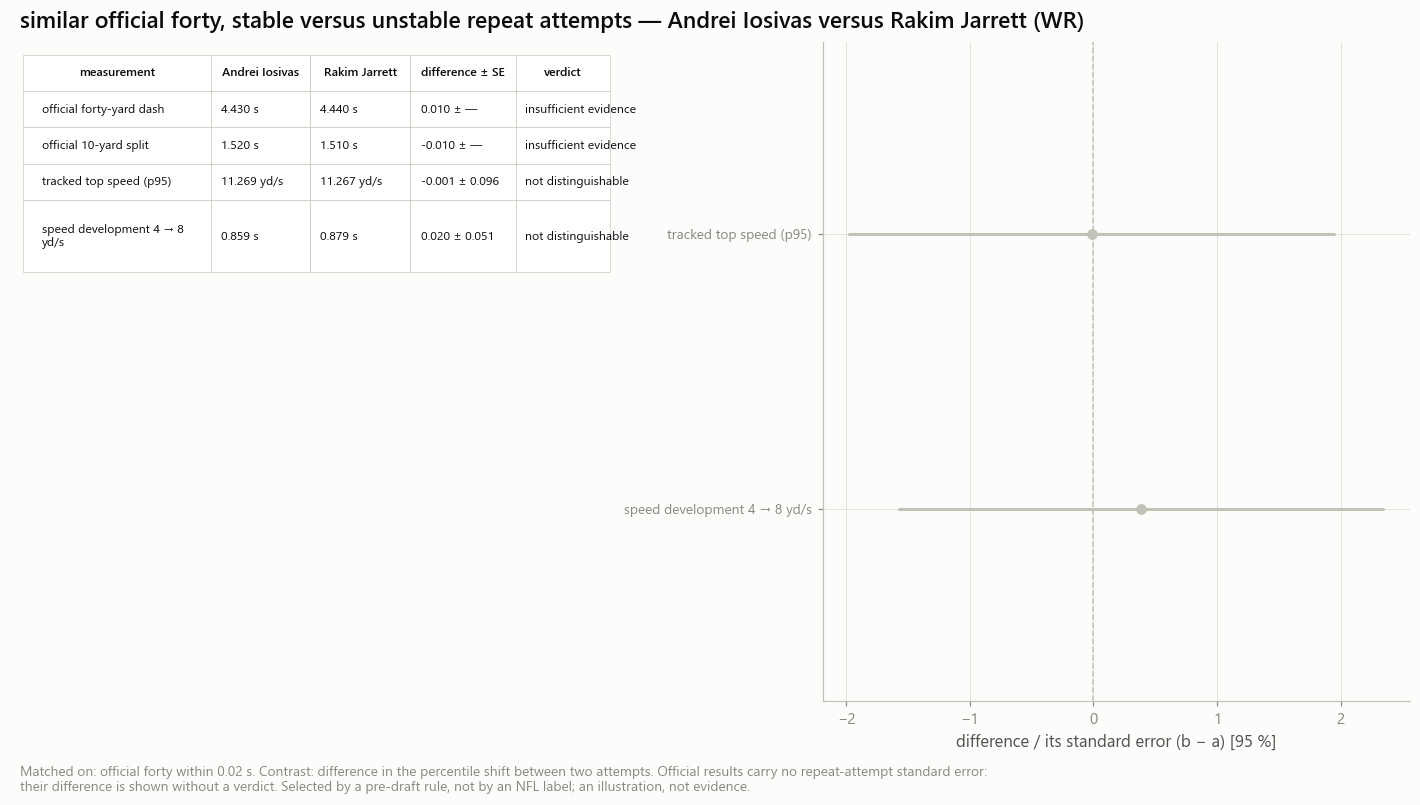

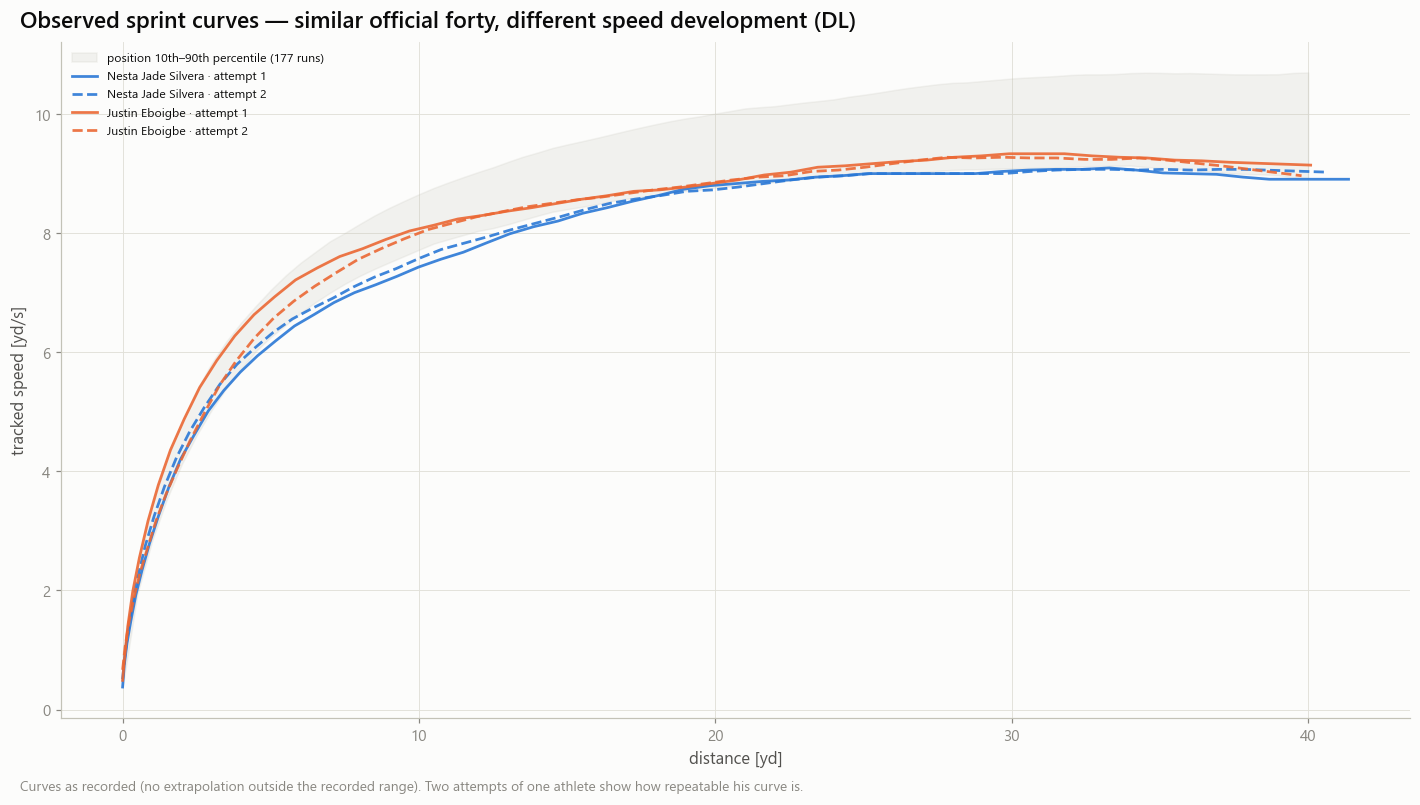

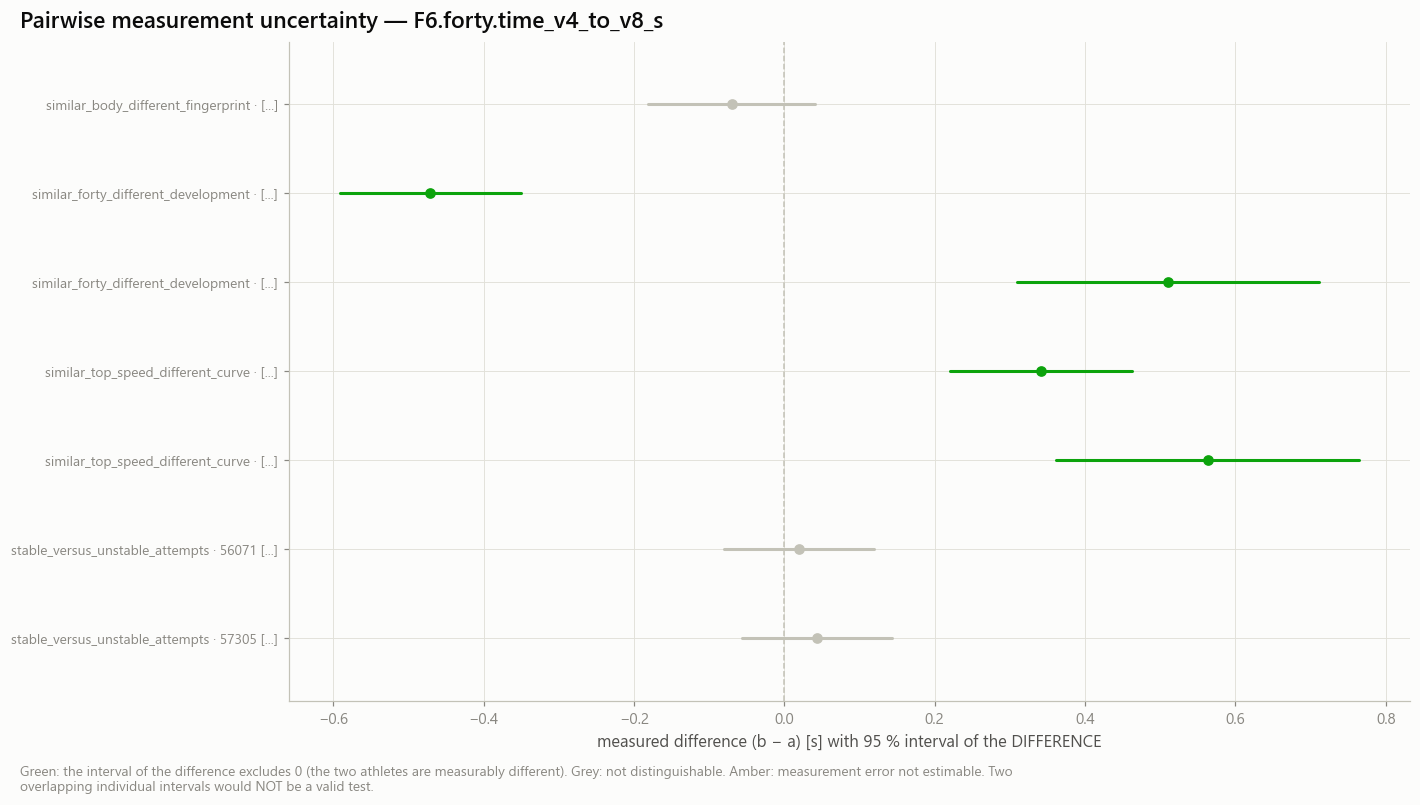

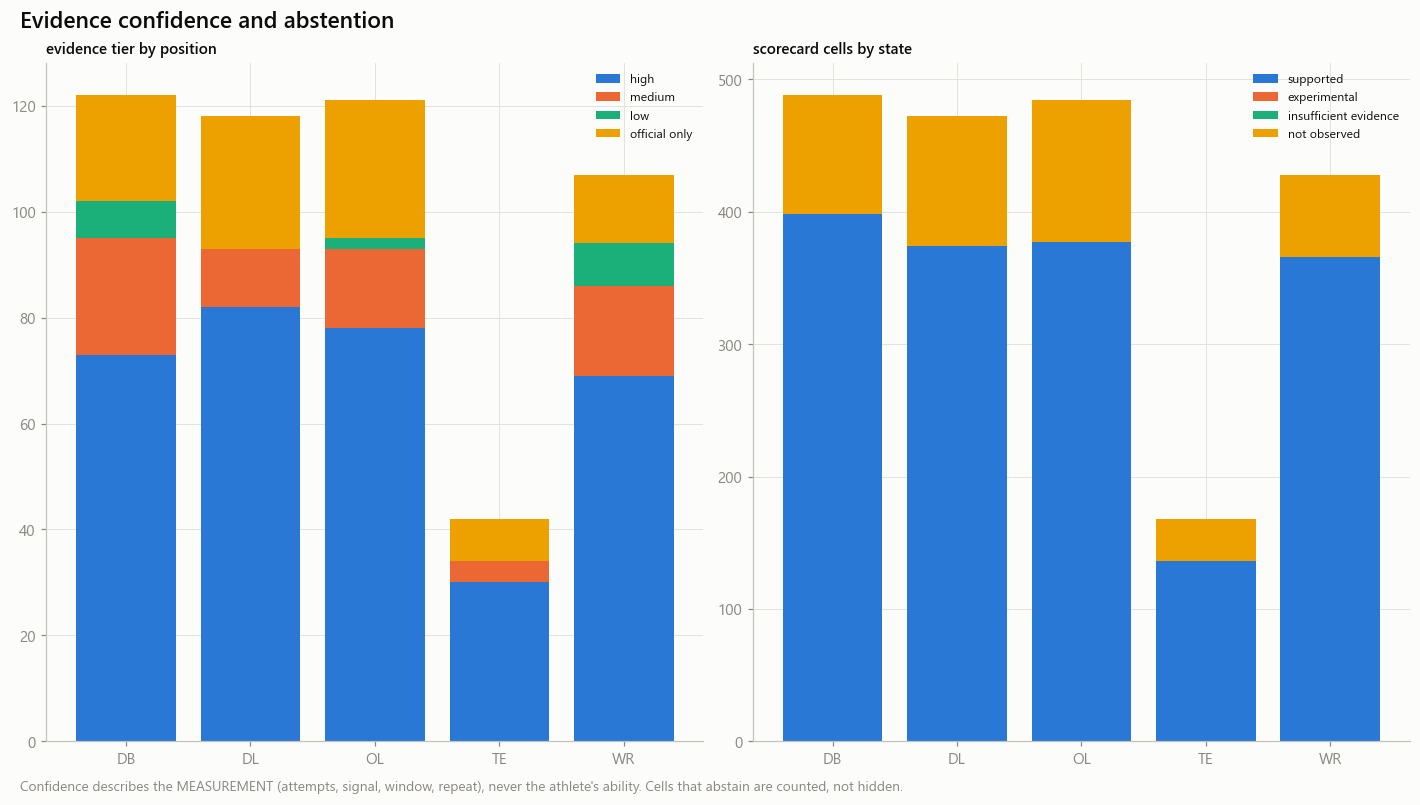

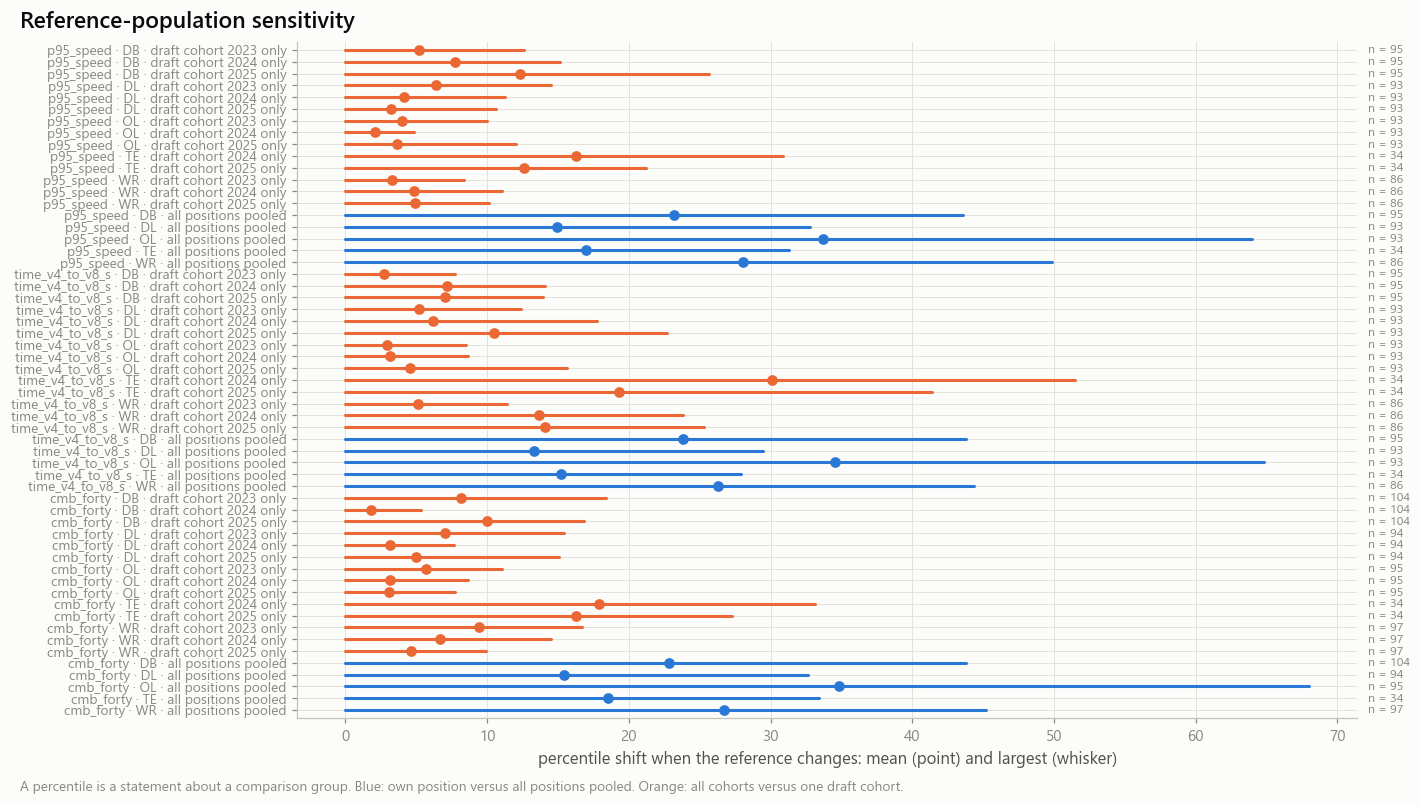

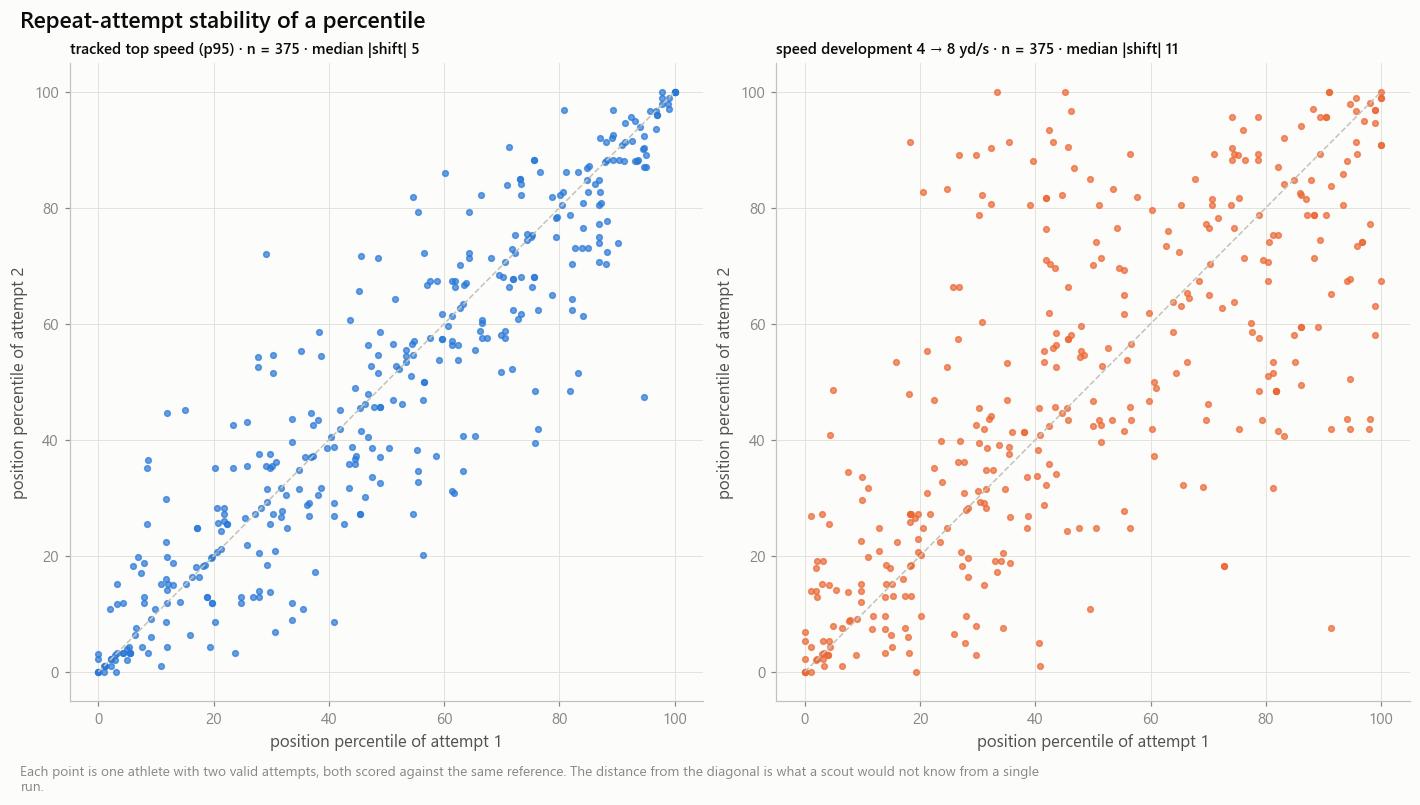

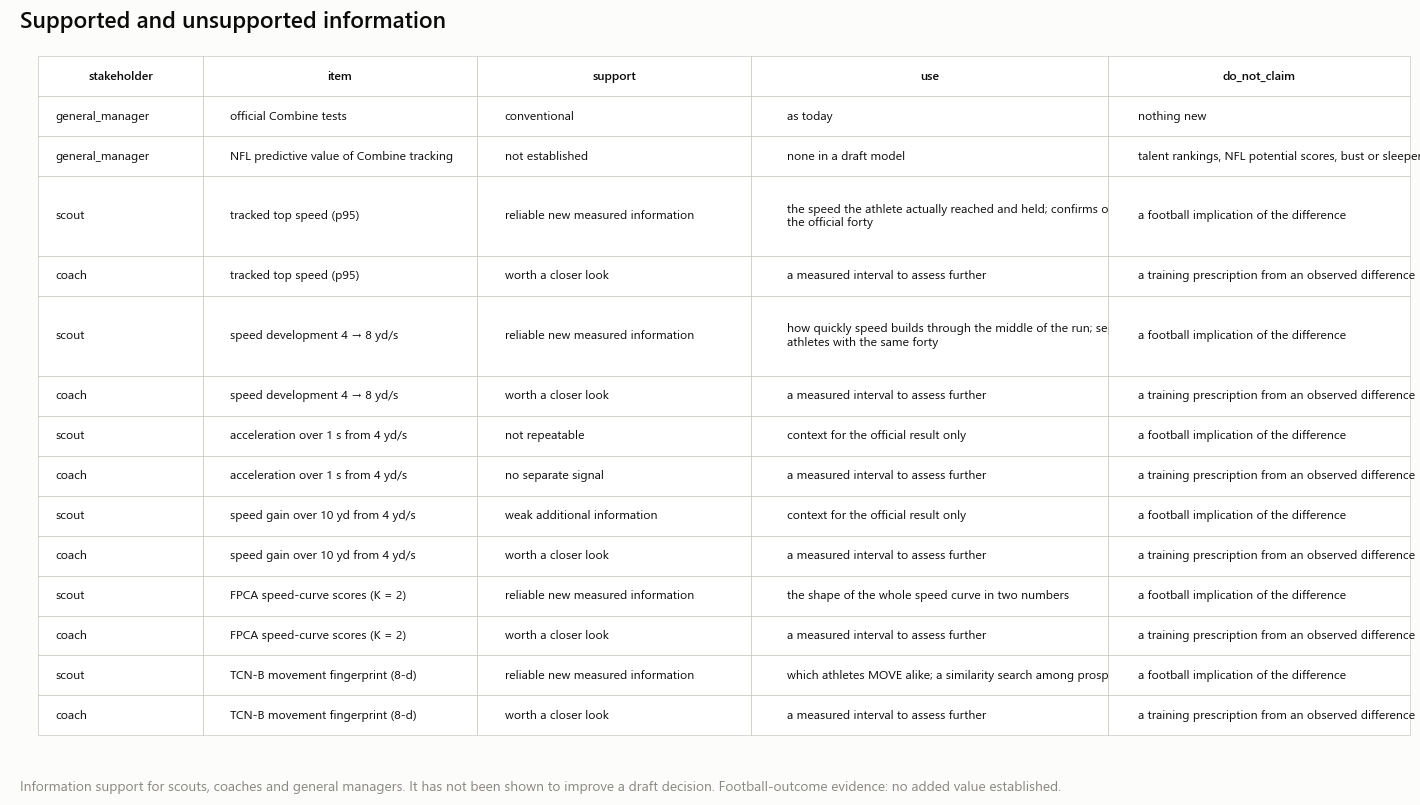

In [8]:
PROFILE = {r['nfl_id']: r for r in profile.iter_rows(named=True)}
first_cases = cases.filter(pl.col('rank') == 1)
card_ids = list(dict.fromkeys([i for r in first_cases.iter_rows(named=True) for i in (r['nfl_id_a'], r['nfl_id_b'])]))[:MAX_SCORECARDS]
if not card_ids:
    card_ids = profile.filter(pl.col('fingerprint_available'))['nfl_id'].head(MAX_SCORECARDS).to_list()
for i in card_ids:
    nb_ = neighbors.filter((pl.col('nfl_id') == i) & (pl.col('kind') == 'position')).sort('rank').head(3)
    store.show(ff.fig_scorecard(PROFILE[i], pct, states, [NAME.get(j, str(j)) for j in nb_['neighbor_id'].to_list()], PANEL), f'AM08B5_01_scouting_scorecard_{i}',
               {'percentiles': pct.filter(pl.col('nfl_id') == i)}, publication=True, source='07D scorecard tables + scouting_evidence_states', n='one athlete; reference sizes in the table')
for r in first_cases.iter_rows(named=True):
    store.show(ff.fig_two_players(r, pairwise), f'AM08B5_02_two_player_comparison_{r["case"]}', {'pairwise': pairwise.filter(pl.col('case') == r['case'])},
               publication=True, source='scouting_pairwise_uncertainty', n='two athletes')
if frames is not None and first_cases.height:
    r = first_cases.row(0, named=True)
    seqs = lambda i: windows.filter(pl.col('nfl_id') == i).sort('attempt_order')['seq_id'].to_list()[:2]
    curves = {r[k]: [c for s in seqs(r[j]) for c in sfig.athlete_curves(frames, [s])] for k, j in (('name_a', 'nfl_id_a'), ('name_b', 'nfl_id_b'))}
    band = sfig.curve_band(frames, windows.filter(pl.col('position_group') == r['position_group'])['seq_id'].to_list())
    store.show(ff.fig_curve_overlay(curves, band, f'Observed sprint curves — {r["criterion"]} ({r["position_group"]})'), 'AM08B5_03_observed_sprint_curve_overlay', {},
               publication=True, source='sequence_frames', n='recorded attempts of two athletes')
else:
    print('sprint-curve overlay skipped: no sequence frames or no comparison case')
store.show(ff.fig_pairwise(pairwise, pc.V4_V8), 'AM08B5_04_pairwise_uncertainty', {'pairwise': pairwise}, publication=True, source='scouting_pairwise_uncertainty',
           n=f'{cases.height} comparison cases')
store.show(ff.fig_confidence(confidence, states), 'AM08B5_05_evidence_confidence', {'states': states.group_by('position_group', 'state').len()},
           source='combine_measurement_confidence + scouting_evidence_states', n=f'{confidence.height} athletes')
store.show(ff.fig_reference_sensitivity(ref_sens), 'AM08B5_06_reference_population_sensitivity', {'reference': ref_sens}, source='scouting_reference_sensitivity',
           n='athletes scored (annotated)')
store.show(ff.fig_attempt_stability(shifts, FEATURE_LABELS), 'AM08B5_07_repeat_attempt_stability', {'summary': shift_summary}, publication=True,
           source='scouting_attempt_percentile_shifts', n='athletes with two valid attempts')
store.show(ff.fig_reading(summary, ['stakeholder', 'item', 'support', 'use', 'do_not_claim'], 'Supported and unsupported information',
                          'Information support for scouts, coaches and general managers. It has not been shown to improve a draft decision. ' + PANEL['title'] + '.',
                          [0.12, 0.2, 0.2, 0.26, 0.22]),
           'AM08B5_08_supported_unsupported_information', {'summary': summary}, publication=True, source='scouting_information_summary', n='characteristics of the 08B.4 registry')

## 7 · Gate E — scouting scorecard

Are the scores descriptive, honest, stable and uncertainty-aware? No NFL input · no total or potential score · an interval on every tracked percentile · explicit abstention · cases selected pre-draft · pairwise tests on differences · repeat-attempt stability reported. A criterion that fails requires abstention or a displayed limitation — not a hidden fix.

In [9]:
gate = save(si.gate_e(profile, pct, states, cases, pairwise, shift_summary, PANEL), si.GATE_E)
GATE_E = 'PASS' if bool(gate['passed'].all()) else 'FAIL'
with pl.Config(fmt_str_lengths=220, tbl_rows=-1):
    display(gate)
if controls.save_tables:
    store.write_json('scouting_intelligence_manifest', {
        'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'gate_e': GATE_E, 'football_panel': PANEL, 'branch': BRANCH,
        'n_profiles': profile.height, 'n_cases': cases.height, 'case_types_found': sorted(found), 'scorecard_athletes': card_ids, 'provenance': PROV})
print('Gate E:', GATE_E)

23:43:00 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B5] football_gate_e_scorecard: 8 rows → warehouse/gold/advanced_movement/football_v1/football_gate_e_scorecard.parquet


criterion,passed,detail
str,bool,str
"""no_nfl_input""",true,"""no NFL-named column in the profile, percentile or case tables"""
"""no_total_or_potential_score""",true,"""the four sections are never combined"""
"""uncertainty_displayed""",true,"""802 tracked percentile(s), each with an interval"""
"""abstention_explicit""",true,"""389 cell(s) abstain with a stated reason"""
"""cases_selected_pre_draft""",true,"""10 case(s), none selected with an NFL label"""
"""pairwise_tests_on_differences""",true,"""verdicts use the standard error of the difference"""
"""repeat_attempt_stability_reported""",true,"""12 feature × position row(s)"""
"""football_panel_matches_validation""",true,"""Football-outcome evidence: no added value established"""


Gate E: PASS


## 8 · Reading

- **For a scout:** two prospects with the same forty can have measurably different speed development — when the *difference* exceeds its standard error. When it does not, the scorecard says *not distinguishable*.
- **For a coach:** a recorded difference in a speed interval is an interval worth assessing further. It is not a training prescription.
- **For a general manager:** the summary table separates conventional information, reliable new measured information, duplicated information, experimental representations and what cannot be claimed.

**Send back:** the checks table, the state counts, the shift summary, the cases and pairwise tables, the panel line, Gate E, figures `AM08B5_01`, `02`, `04`, `07`, `08`.

**Next:** `08b6_final_research_evidence_package.ipynb`.